# Inicialización de archivos

Este notebook realiza la inicialización, exploración de los datos y restructuración para poderlo implementar al modelo.

El proceso de este notebook es el siguiente:
1. Montar Google Drive el cual almacena el dataset.
2. Lee el dataset original sin modificarlo.
3. Audita imágenes, explorando a través de un sample por categoría.
4. Crea físicamente *train*, *val* y *test* en carpetas separadas, con división estratificada de 80/5/15 respectivamente.

En este caso, se debe ajustar la ruta a donde está almacenado la información del dataset. Dentro de el existen carpetas de glioma, meningioma, pituitario y sano.

Tras correr el código, se obtiene carpetas divididas las cuales ya se pueden utilizar para la red neuronal.

### Librerías

In [ ]:
%pip -q install scikit-learn seaborn pillow

import os
import shutil
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from sklearn.model_selection import train_test_split


SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("GPU(s):", tf.config.list_physical_devices("GPU"))

Note: you may need to restart the kernel to use updated packages.
GPU(s): []


## Configurar rutas e inicializar dataset

- *RAW_DIR*: carpeta que contiene los datos originales en Drive.
- *PROJECT_DIR*: carpeta donde se crearán las particiones y se guardará el modelo.


In [17]:
RAW_DIR = Path("/Users/sebaschitiva/Desktop/Concentración_IA_Avanzada/Periodo_Avanzado/Proyecto/Dataset_raw")
PROJECT_DIR = Path("/Users/sebaschitiva/Desktop/Concentración_IA_Avanzada/Periodo_Avanzado/Proyecto")

SPLIT_DIR = PROJECT_DIR / "dataset_split"
MODEL_DIR = PROJECT_DIR / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Datos originales:", RAW_DIR)
print("Carpeta de proyecto:", PROJECT_DIR)

Datos originales: /Users/sebaschitiva/Desktop/Concentración_IA_Avanzada/Periodo_Avanzado/Proyecto/Dataset_raw
Carpeta de proyecto: /Users/sebaschitiva/Desktop/Concentración_IA_Avanzada/Periodo_Avanzado/Proyecto


## Auditoría de datos

### Visualización de carpetas

Se inspeccionan los nombres de las carpetas que contiene el dataset en crudo, junto con el número de archivos dentro de cada carpeta.

In [18]:
for root, dirs, files in os.walk(RAW_DIR):
    depth = len(Path(root).relative_to(RAW_DIR).parts)
    if depth <= 3:
        print("  " * depth + Path(root).name + f"/ ({len(files)} archivo/s)")

Dataset_raw/ (1 archivo/s)
  pituitary/ (2706 archivo/s)
  no_tumor/ (1757 archivo/s)
  glioma/ (3754 archivo/s)
  meningioma/ (2343 archivo/s)


### Detección y conteo de clases

Se agrupan de la siguiente manera las clases internas, esto con el propósito de mantener estructurado y no tener información mal clasificada debido a los nombres. La única variante es la clase de sanos, las cuales se renombran de "no_tumor" a "healthy". Al realizar los cambios, las categorías se llaman de la siguiente manera.

* glioma
* meningioma
* pituitary
* healthy

De igual forma, se muestra el número de imágenes por cada clase como validación respecto al punto anterior.

In [19]:
CLASS_NAMES = {
    "glioma": "glioma",
    "meningioma": "meningioma",
    "pituitary": "pituitary",
    "no_tumor": "healthy"
}

CLASES = ["glioma", "meningioma", "pituitary", "healthy"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

class_counts = {}

for nombre_folder, nombre_clase in CLASS_NAMES.items():
    folders = [
        folder for folder in RAW_DIR.rglob("*")
        if folder.is_dir() and folder.name.lower() == nombre_folder
    ]

    count = sum(
        1 for folder in folders
        for file in folder.rglob("*")
        if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
    )

    class_counts[nombre_clase] = count

    print(f"{nombre_clase}: {count} imágenes")
    for folder in folders:
        print(f" Ruta: {folder}")

summary = pd.DataFrame({
    "Clase": CLASES,
    "Cantidad de imágenes": [class_counts[c] for c in CLASES]
})

print(f"\nTotal de imágenes: {sum(class_counts.values())}")
display(summary)

glioma: 3754 imágenes
 Ruta: /Users/sebaschitiva/Desktop/Concentración_IA_Avanzada/Periodo_Avanzado/Proyecto/Dataset_raw/glioma
meningioma: 2343 imágenes
 Ruta: /Users/sebaschitiva/Desktop/Concentración_IA_Avanzada/Periodo_Avanzado/Proyecto/Dataset_raw/meningioma
pituitary: 2706 imágenes
 Ruta: /Users/sebaschitiva/Desktop/Concentración_IA_Avanzada/Periodo_Avanzado/Proyecto/Dataset_raw/pituitary
healthy: 1757 imágenes
 Ruta: /Users/sebaschitiva/Desktop/Concentración_IA_Avanzada/Periodo_Avanzado/Proyecto/Dataset_raw/no_tumor

Total de imágenes: 10560


,Clase,Cantidad de imágenes
0,glioma,3754
1,meningioma,2343
2,pituitary,2706
3,healthy,1757


### Inicialización

In [20]:
# Crear inventario de imágenes
records = []

for nombre_folder, label in CLASS_NAMES.items():
    folders = [
        folder for folder in RAW_DIR.rglob("*")
        if folder.is_dir() and folder.name.lower() == nombre_folder
    ]

    for folder in folders:
        for path in folder.rglob("*"):
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
                records.append({
                    "Ruta": str(path),
                    "label": label
                })

df = pd.DataFrame(records).drop_duplicates(
    subset="Ruta"
).reset_index(drop=True)

#Visualización al inventario de imagenes
print(f"Imágenes registradas: {len(df)}")
display(df.head())
display(df["label"].value_counts())

Imágenes registradas: 10560


,Ruta,label
0,/Users/sebaschitiva/Desktop/Concentración_IA_A...,glioma
1,/Users/sebaschitiva/Desktop/Concentración_IA_A...,glioma
2,/Users/sebaschitiva/Desktop/Concentración_IA_A...,glioma
3,/Users/sebaschitiva/Desktop/Concentración_IA_A...,glioma
4,/Users/sebaschitiva/Desktop/Concentración_IA_A...,glioma


label
glioma        3754
pituitary     2706
meningioma    2343
healthy       1757
Name: count, dtype: int64

## Conteo y distribución de imágenes por clase

Visualización de la cantidad de imagenes por cada clase, junto con su porcentaje

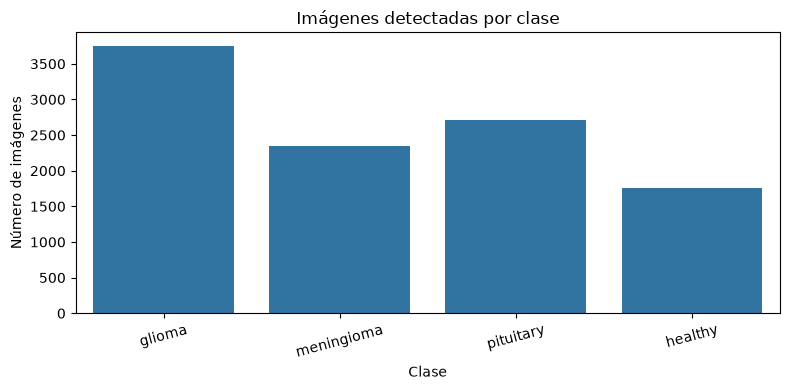

label
glioma        35.55
meningioma    22.19
pituitary     25.62
healthy       16.64
Name: count, dtype: float64


In [21]:
conteo = df["label"].value_counts().reindex(CLASES, fill_value=0)

#Visualización
plt.figure(figsize=(8, 4))
sns.barplot(x=conteo.index, y=conteo.values)
plt.title("Imágenes detectadas por clase")
plt.xlabel("Clase")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print((conteo / conteo.sum() * 100).round(2))

In [25]:
# Lista para guardar la información de las imágenes
image_info = []

# Revisar todas las imágenes del dataset
for fila in df.itertuples(index=False):

    with Image.open(fila.Ruta) as img:

        image_info.append({
            "clase": fila.label,
            "archivo": Path(fila.Ruta).name,
            "ancho": img.width,
            "alto": img.height,
            "modo_color": img.mode,
            "formato": img.format
        })

# Crear una tabla con la información recopilada
audit_df = pd.DataFrame(image_info)

# Mostrar los primeros 10 registros
display(audit_df.head(10))

# Mostrar el total de imágenes revisadas
print(f"Total de imágenes revisadas: {len(audit_df)}")

# Mostrar la cantidad de imágenes según su modo de color
display(audit_df["modo_color"].value_counts().to_frame("Cantidad"))

# Mostrar la cantidad de imágenes según sutipo de imagen
display(audit_df["formato"].value_counts().to_frame("Formato"))

,clase,archivo,ancho,alto,modo_color,formato
0,glioma,glioma2013.jpg,512,512,L,JPEG
1,glioma,glioma768.png,512,512,RGBA,PNG
2,glioma,glioma2775.jpg,512,512,L,JPEG
3,glioma,glioma2761.jpg,512,512,L,JPEG
4,glioma,glioma2007.jpg,512,512,L,JPEG
5,glioma,glioma3319.jpg,512,512,RGB,JPEG
6,glioma,glioma754.png,512,512,RGBA,PNG
7,glioma,glioma3331.jpg,512,512,RGB,JPEG
8,glioma,glioma1526.jpg,512,512,L,JPEG
9,glioma,glioma3457.jpg,512,512,RGB,JPEG


Total de imágenes revisadas: 10560


,Cantidad
modo_color,
RGB,4392
L,3099
RGBA,3068
P,1


,Formato
formato,
JPEG,7490
PNG,3070


In [26]:
resumen_auditoria = audit_df.groupby("clase").agg(
    imagenes_revisadas=("archivo", "count"),
    ancho_promedio=("ancho", "mean"),
    alto_promedio=("alto", "mean"),
    modos_color=("modo_color", "nunique"),
    formatos=("formato", "nunique")
).round(2)

display(resumen_auditoria)

,imagenes_revisadas,ancho_promedio,alto_promedio,modos_color,formatos
clase,,,,,
glioma,3754,509.65,510.10,3,2
healthy,1757,306.78,311.68,4,2
meningioma,2343,492.21,494.05,3,2
pituitary,2706,509.63,509.52,3,2


## Auditoría de tamaños

### Histograma de anchos y altos de imágenes

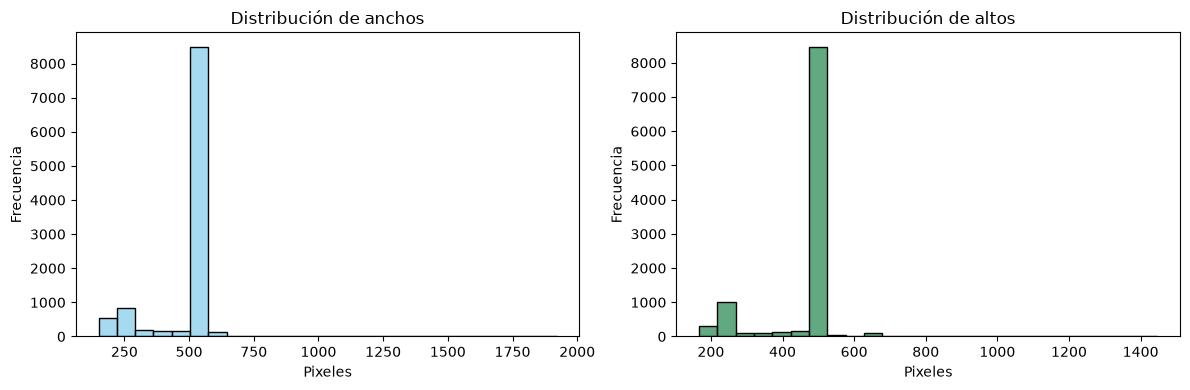

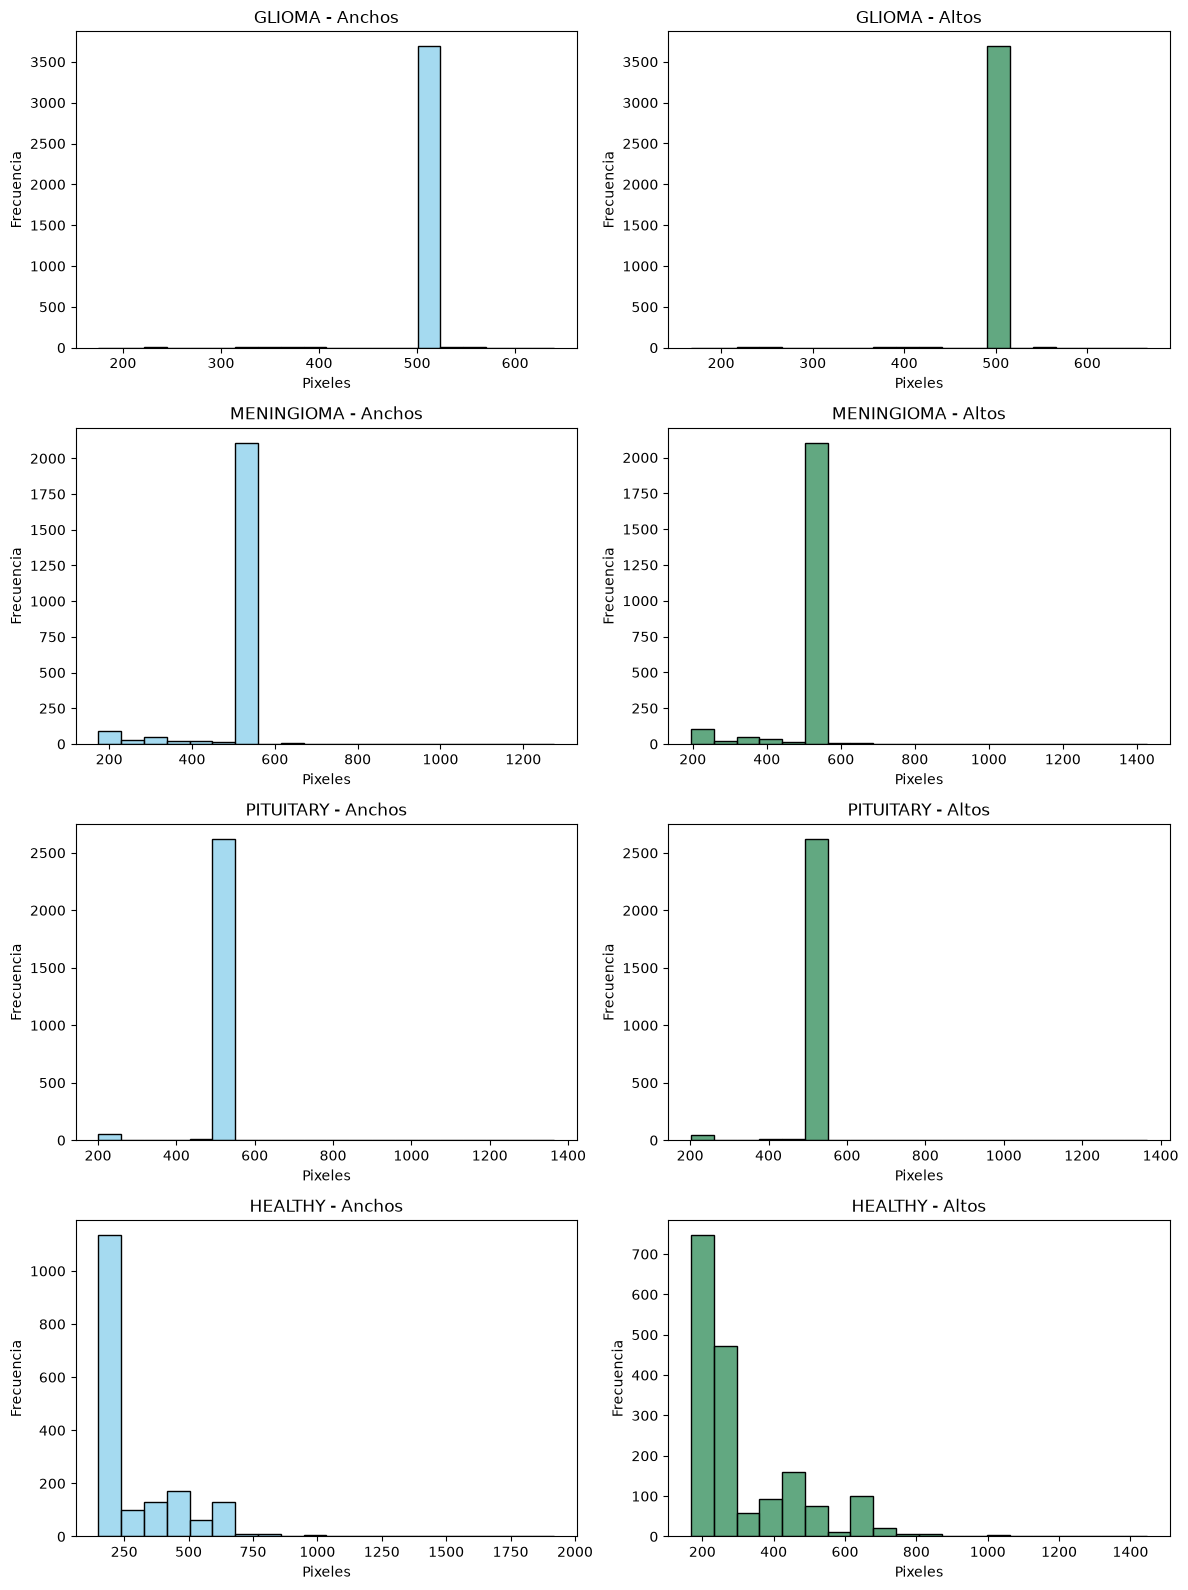

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(audit_df["ancho"], bins=25, ax=axes[0], color="skyblue")
axes[0].set_title("Distribución de anchos")
axes[0].set_xlabel("Pixeles")
axes[0].set_ylabel("Frecuencia")

sns.histplot(audit_df["alto"], bins=25, ax=axes[1], color="seagreen")
axes[1].set_title("Distribución de altos")
axes[1].set_xlabel("Pixeles")
axes[1].set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

# Distribución por categoría
fig, axes = plt.subplots(len(CLASES), 2, figsize=(12, 4 * len(CLASES)))

for idx, cls in enumerate(CLASES):
    class_subset = audit_df[audit_df["clase"] == cls]

    # Ancho por clase
    sns.histplot(class_subset["ancho"], bins=20, ax=axes[idx, 0], color='skyblue')
    axes[idx, 0].set_title(f"{cls.upper()} - Anchos")
    axes[idx, 0].set_xlabel("Pixeles")
    axes[idx, 0].set_ylabel("Frecuencia")

    # Alto por clase
    sns.histplot(class_subset["alto"], bins=20, ax=axes[idx, 1], color='seagreen')
    axes[idx, 1].set_title(f"{cls.upper()} - Altos")
    axes[idx, 1].set_xlabel("Pixeles")
    axes[idx, 1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

## Visualizar ejemplos de las cuatro clases

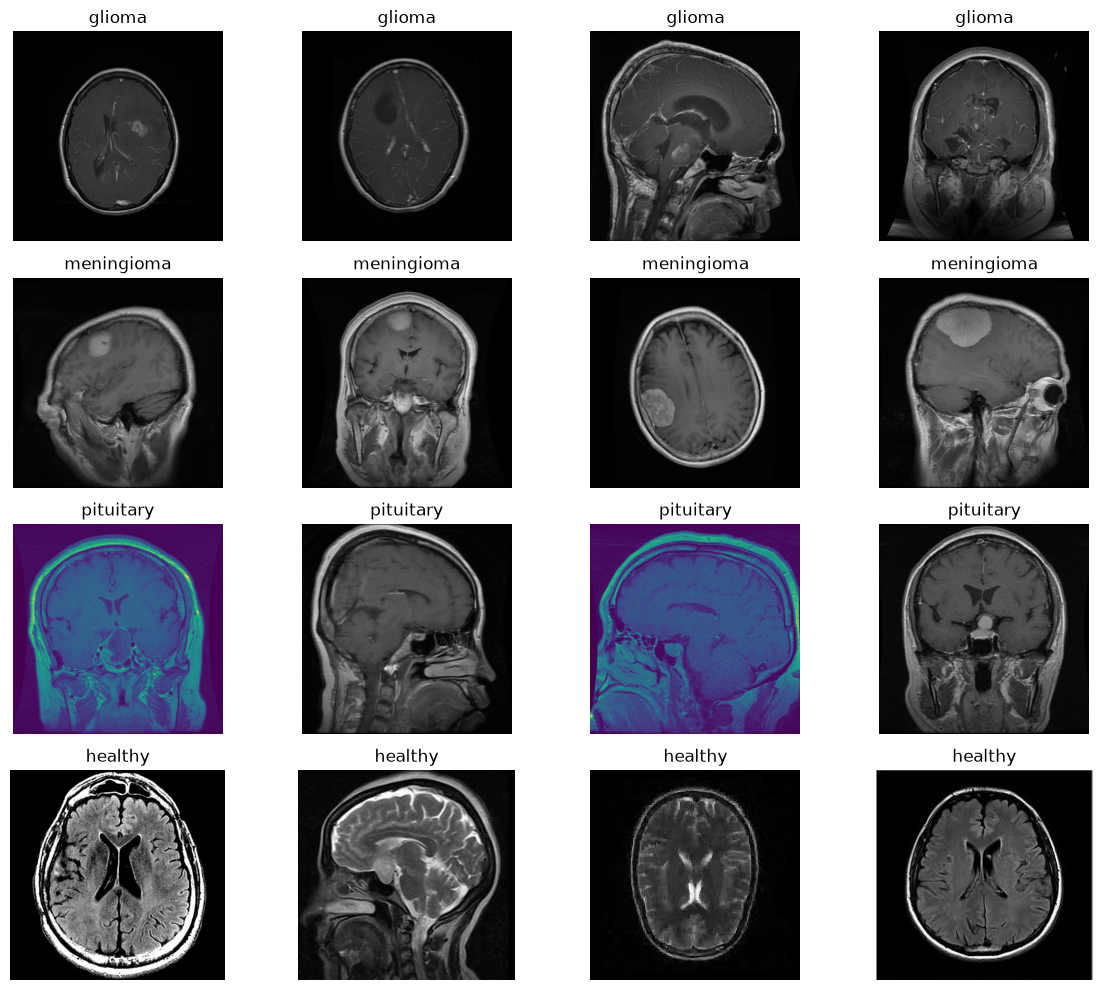

In [ ]:
def mostrar_ejemplos(dataframe, ejemplos_por_clase=4):
    fig, axes = plt.subplots(len(CLASES), ejemplos_por_clase, figsize=(12, 10))
    for i, cls in enumerate(CLASES):
        subset = dataframe[dataframe["label"] == cls]
        elegido = subset.sample(min(ejemplos_por_clase, len(subset)), random_state=SEED)
        for j in range(ejemplos_por_clase):
            ax = axes[i, j]
            ax.axis("off")
            if j < len(elegido):
                with Image.open(elegido.iloc[j]["Ruta"]) as img:
                    ax.imshow(img.convert("RGB"))
                ax.set_title(cls)
    plt.tight_layout()
    plt.show()

mostrar_ejemplos(df, ejemplos_por_clase=4)

## Crear las particiones físicas Train / Validation / Test

Se usará una división **80/5/15**, estratificada por clase:
- Train: 80%
- Validation: 5%
- Test: 15%

In [30]:
TRAIN_RATIO = 0.80
VAL_RATIO = 0.05
TEST_RATIO = 0.15

assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-9

model_df = df.copy().reset_index(drop=True)

# Comprobar si ya existen imágenes en la carpeta de particiones
if SPLIT_DIR.exists() and any(
    file.is_file()
    for file in SPLIT_DIR.rglob("*")
):
    print("Ya existe una partición.")

else:
    print("No se encontraron particiones. Creando subsets")

    # Primera separación: 80% train y 20% temporal.
    train_df, temp_df = train_test_split(
        model_df,
        test_size=(VAL_RATIO + TEST_RATIO),
        random_state=SEED,
        stratify=model_df["label"]
    )

    # Separar el 20% restante en validación y test.
    relative_test_size = TEST_RATIO / (VAL_RATIO + TEST_RATIO)

    val_df, test_df = train_test_split(
        temp_df,
        test_size=relative_test_size,
        random_state=SEED,
        stratify=temp_df["label"]
    )

    splits = {
        "train": train_df,
        "val": val_df,
        "test": test_df
    }

    # Crear carpetas y copiar imágenes.
    for split_name, split_df in splits.items():

        for cls in CLASES:
            (SPLIT_DIR / split_name / cls).mkdir(
                parents=True,
                exist_ok=True
            )

        for idx, fila in split_df.iterrows():
            source = Path(fila["filepath"])

            destination = (
                SPLIT_DIR / split_name / fila["label"] /
                f"{idx:06d}_{source.name}"
            )

            shutil.copy2(source, destination)

    print("Particiones creadas en:", SPLIT_DIR)

Ya existe una partición.
